Dataset downloaded: (72856, 13)
   UserID  ChargerID  ChargerCompany Location  ChargerType    StartDay  \
0       0          1               1    hotel            0  2022-09-15   
1       0          1               1    hotel            0  2022-09-14   
2       0          1               1    hotel            0  2022-09-14   
3       0          1               1    hotel            0  2022-09-29   
4       0          1               1    hotel            0  2022-09-25   

  StartTime      EndDay   EndTime     StartDatetime       EndDatetime  \
0  20:54:02  2022-09-15  23:59:13  2022-09-15 20:54  2022-09-15 23:59   
1  20:01:05  2022-09-14  21:31:04  2022-09-14 20:01  2022-09-14 21:31   
2  18:54:30  2022-09-14  19:54:29  2022-09-14 18:54  2022-09-14 19:54   
3  18:32:51  2022-09-30   0:16:42  2022-09-29 18:32   2022-09-30 0:16   
4  19:30:15  2022-09-26   0:30:14  2022-09-25 19:30   2022-09-26 0:30   

   Duration  Demand  
0       185   20.36  
1        90   10.19  
2        60    6.7

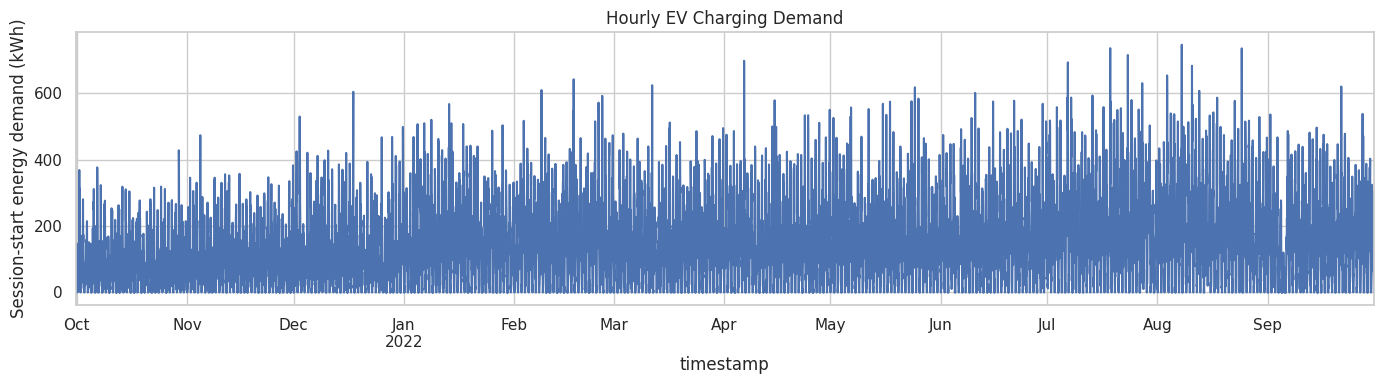

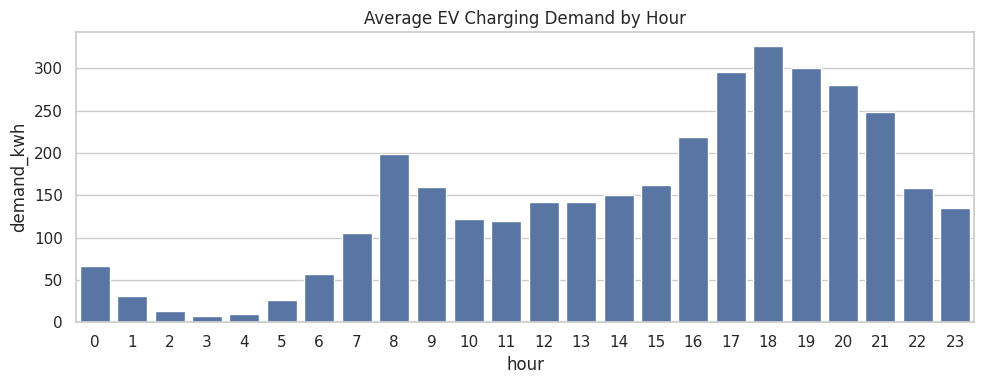

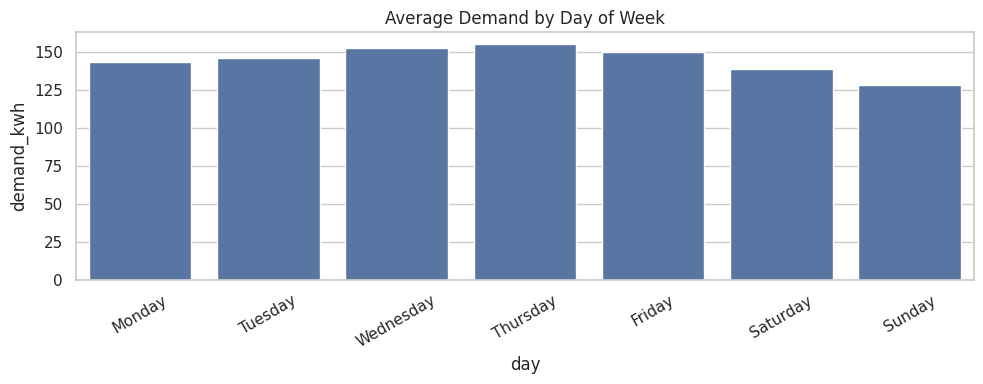


Training observations: 6879
Testing observations: 1720
Test begins: 2022-07-21 08:00:00

Training: Random Forest

Training: Histogram Gradient Boosting

MODEL PERFORMANCE


,Model,MAE,RMSE,R2
1,Random Forest,57.258820,78.056321,0.680591
2,Histogram Gradient Boosting,57.371263,79.380103,0.669665
0,Seasonal Naive (24h),75.242576,104.257049,0.430174


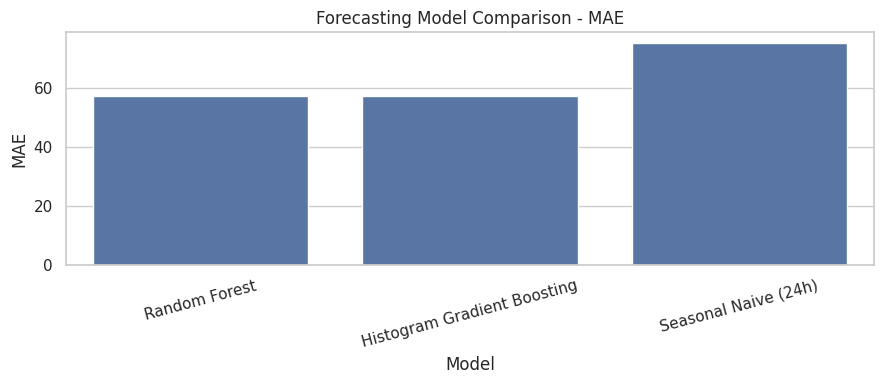


Best model: Random Forest


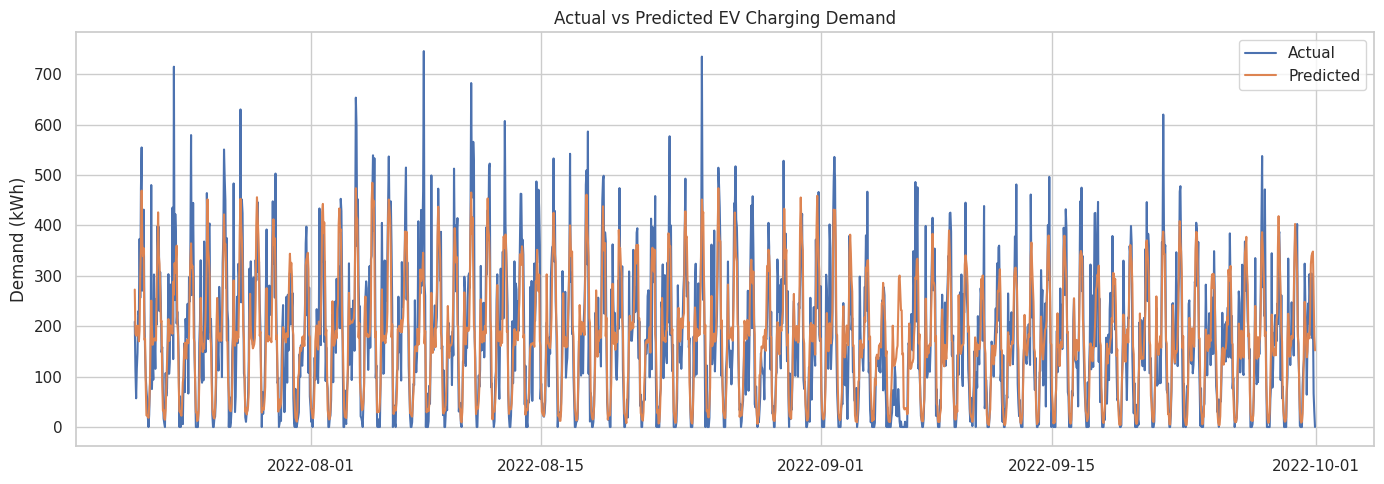

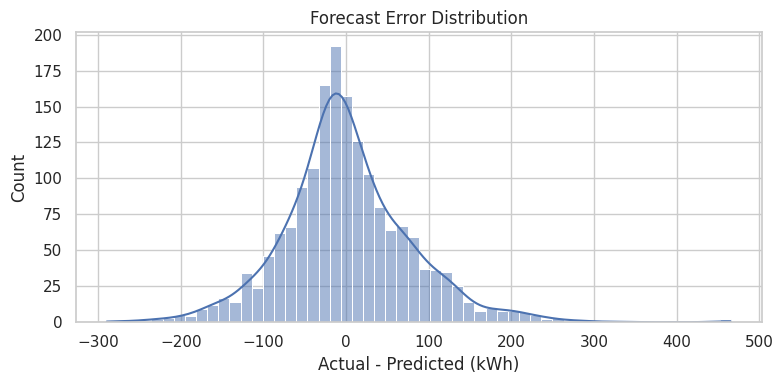

,Feature,Importance
0,hour,33.030524
5,hour_sin,29.230018
6,hour_cos,3.877131
10,lag_24,1.317830
13,rolling_mean_168,1.134540
9,lag_1,1.035811
12,rolling_mean_24,0.703261
11,lag_168,0.701316
1,day_of_week,0.264182
7,day_sin,0.174886


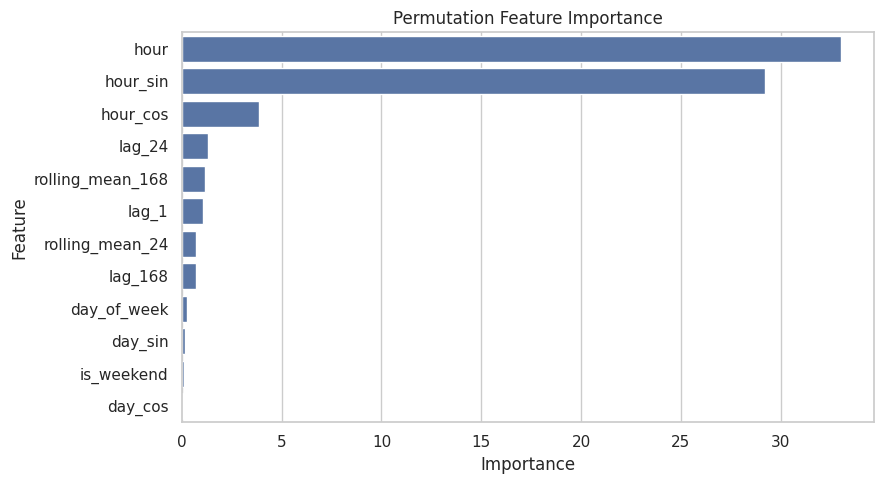


NEXT 24 HOURS FORECAST


,timestamp,predicted_demand_kwh
0,2022-10-01 00:00:00,82.797863
1,2022-10-01 01:00:00,30.005538
2,2022-10-01 02:00:00,11.061364
3,2022-10-01 03:00:00,9.304479
4,2022-10-01 04:00:00,9.303157
5,2022-10-01 05:00:00,27.982730
6,2022-10-01 06:00:00,91.466029
7,2022-10-01 07:00:00,115.560350
8,2022-10-01 08:00:00,159.904797
9,2022-10-01 09:00:00,173.733431


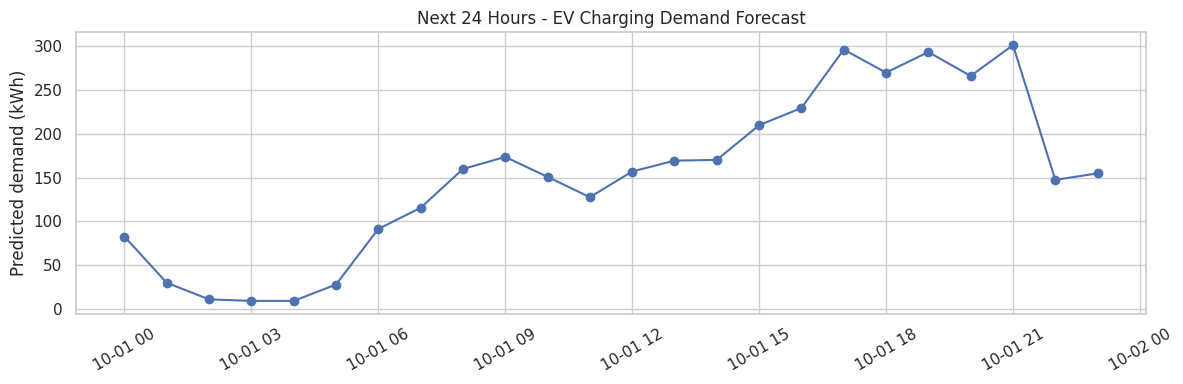


CHARGECAST PROJECT COMPLETED
Best model: Random Forest
MAE: 57.2588
RMSE: 78.0563
R2: 0.6806
Forecast horizon: 24 hours
Export: ChargeCast_Project.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [1]:

# CHARGECAST - EV CHARGING DEMAND FORECASTING

!pip -q install pandas numpy matplotlib seaborn scikit-learn joblib

import os, json, zipfile, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

# 1. DOWNLOAD REAL-WORLD DATASET
URL = "https://ndownloader.figshare.com/files/39952252"
df = pd.read_csv(URL)

print("Dataset downloaded:", df.shape)
print(df.head())
print("\nColumns:", df.columns.tolist())

# 2. STANDARDIZE COLUMN NAMES
df.columns = (
    df.columns.str.strip()
    .str.lower()
    .str.replace(" ", "", regex=False)
    .str.replace("_", "", regex=False)
)

date_candidates = ["startdatetime", "srartdatetime"]
date_col = next((c for c in date_candidates if c in df.columns), None)

if date_col is None:
    if "startday" in df.columns and "starttime" in df.columns:
        df["startdatetime"] = (
            df["startday"].astype(str) + " " +
            df["starttime"].astype(str)
        )
        date_col = "startdatetime"
    else:
        raise ValueError("Could not find charging session start date.")

if "demand" not in df.columns:
    raise ValueError("Demand column not found in downloaded dataset.")

df["timestamp"] = pd.to_datetime(
    df[date_col], errors="coerce"
)

df["demand"] = pd.to_numeric(
    df["demand"], errors="coerce"
)

df = df.dropna(subset=["timestamp", "demand"])
df = df[df["demand"] >= 0].copy()
df = df.drop_duplicates()

print("\nCleaned session records:", len(df))

# 3. CREATE HOURLY DEMAND SERIES
# Demand is assigned to the hour in which each charging
# session starts. This is a session-start demand proxy.

hourly = (
    df.set_index("timestamp")["demand"]
    .resample("h").sum()
    .asfreq("h", fill_value=0)
)

hourly.name = "demand_kwh"

print("\nHourly observations:", len(hourly))
print(hourly.describe())

# 4. EXPLORATORY DATA ANALYSIS
plt.figure(figsize=(14, 4))
hourly.plot()
plt.title("Hourly EV Charging Demand")
plt.ylabel("Session-start energy demand (kWh)")
plt.tight_layout()
plt.savefig("chargecast_hourly_demand.png")
plt.show()

hourly_df = hourly.to_frame()
hourly_df["hour"] = hourly_df.index.hour
hourly_df["day"] = hourly_df.index.day_name()
hourly_df["month"] = hourly_df.index.month

plt.figure(figsize=(10, 4))
sns.barplot(data=hourly_df, x="hour", y="demand_kwh",
            errorbar=None)
plt.title("Average EV Charging Demand by Hour")
plt.tight_layout()
plt.savefig("chargecast_hourly_pattern.png")
plt.show()

plt.figure(figsize=(10, 4))
sns.barplot(data=hourly_df, x="day", y="demand_kwh",
            order=["Monday", "Tuesday", "Wednesday",
                   "Thursday", "Friday", "Saturday", "Sunday"],
            errorbar=None)
plt.xticks(rotation=30)
plt.title("Average Demand by Day of Week")
plt.tight_layout()
plt.savefig("chargecast_weekday_pattern.png")
plt.show()

# 5. FEATURE ENGINEERING
def create_features(series):
    X = pd.DataFrame(index=series.index)

    X["hour"] = series.index.hour
    X["day_of_week"] = series.index.dayofweek
    X["day_of_month"] = series.index.day
    X["month"] = series.index.month
    X["is_weekend"] = (series.index.dayofweek >= 5).astype(int)

    X["hour_sin"] = np.sin(2 * np.pi * X["hour"] / 24)
    X["hour_cos"] = np.cos(2 * np.pi * X["hour"] / 24)
    X["day_sin"] = np.sin(2 * np.pi * X["day_of_week"] / 7)
    X["day_cos"] = np.cos(2 * np.pi * X["day_of_week"] / 7)

    X["lag_1"] = series.shift(1)
    X["lag_24"] = series.shift(24)
    X["lag_168"] = series.shift(168)

    X["rolling_mean_24"] = series.shift(1).rolling(24).mean()
    X["rolling_mean_168"] = series.shift(1).rolling(168).mean()

    return X

X_all = create_features(hourly)
dataset = X_all.copy()
dataset["target"] = hourly
dataset = dataset.dropna()

FEATURES = X_all.columns.tolist()

# 6. CHRONOLOGICAL TRAIN-TEST SPLIT
split = int(len(dataset) * 0.80)

X_train = dataset[FEATURES].iloc[:split]
X_test = dataset[FEATURES].iloc[split:]

y_train = dataset["target"].iloc[:split]
y_test = dataset["target"].iloc[split:]

print("\nTraining observations:", len(X_train))
print("Testing observations:", len(X_test))
print("Test begins:", X_test.index.min())

# 7. TRAIN FORECASTING MODELS
models = {
    "Random Forest": RandomForestRegressor(
        n_estimators=250,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),
    "Histogram Gradient Boosting": HistGradientBoostingRegressor(
        max_iter=250,
        learning_rate=0.06,
        max_leaf_nodes=20,
        l2_regularization=1.0,
        random_state=42
    )
}

results = []
trained_models = {}

# Seasonal naive baseline: same hour on previous day
baseline_predictions = X_test["lag_24"].values

results.append({
    "Model": "Seasonal Naive (24h)",
    "MAE": mean_absolute_error(y_test, baseline_predictions),
    "RMSE": np.sqrt(mean_squared_error(y_test, baseline_predictions)),
    "R2": r2_score(y_test, baseline_predictions)
})

for name, model in models.items():
    print("\nTraining:", name)

    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R2": r2_score(y_test, pred)
    })

    trained_models[name] = model

# 8. COMPARE MODELS
results_df = pd.DataFrame(results).sort_values("MAE")

print("\nMODEL PERFORMANCE")
display(results_df)

plt.figure(figsize=(9, 4))
sns.barplot(data=results_df, x="Model", y="MAE")
plt.title("Forecasting Model Comparison - MAE")
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig("chargecast_model_comparison.png")
plt.show()

best_name = results_df.iloc[0]["Model"]

if best_name == "Seasonal Naive (24h)":
    best_model = None
    best_predictions = baseline_predictions
else:
    best_model = trained_models[best_name]
    best_predictions = best_model.predict(X_test)

print("\nBest model:", best_name)

# 9. ACTUAL VS PREDICTED
plt.figure(figsize=(14, 5))
plt.plot(y_test.index, y_test.values, label="Actual")
plt.plot(y_test.index, best_predictions, label="Predicted")
plt.title("Actual vs Predicted EV Charging Demand")
plt.ylabel("Demand (kWh)")
plt.legend()
plt.tight_layout()
plt.savefig("chargecast_actual_vs_predicted.png")
plt.show()

# 10. PREDICTION RESIDUAL ANALYSIS
residuals = y_test.values - best_predictions

plt.figure(figsize=(8, 4))
sns.histplot(residuals, kde=True)
plt.title("Forecast Error Distribution")
plt.xlabel("Actual - Predicted (kWh)")
plt.tight_layout()
plt.savefig("chargecast_residuals.png")
plt.show()

# 11. FEATURE IMPORTANCE
if best_model is not None:
    importance = permutation_importance(
        best_model,
        X_test,
        y_test,
        n_repeats=3,
        random_state=42,
        scoring="neg_mean_absolute_error"
    )

    importance_df = pd.DataFrame({
        "Feature": FEATURES,
        "Importance": importance.importances_mean
    }).sort_values("Importance", ascending=False)

    display(importance_df)

    plt.figure(figsize=(9, 5))
    sns.barplot(data=importance_df.head(12),
                x="Importance", y="Feature")
    plt.title("Permutation Feature Importance")
    plt.tight_layout()
    plt.savefig("chargecast_feature_importance.png")
    plt.show()
else:
    importance_df = pd.DataFrame()

# 12. FORECAST NEXT 24 HOURS RECURSIVELY
history = hourly.copy()
future_rows = []

for _ in range(24):
    next_time = history.index[-1] + pd.Timedelta(hours=1)

    row = pd.DataFrame(index=[next_time])
    row["hour"] = next_time.hour
    row["day_of_week"] = next_time.dayofweek
    row["day_of_month"] = next_time.day
    row["month"] = next_time.month
    row["is_weekend"] = int(next_time.dayofweek >= 5)

    row["hour_sin"] = np.sin(2 * np.pi * next_time.hour / 24)
    row["hour_cos"] = np.cos(2 * np.pi * next_time.hour / 24)
    row["day_sin"] = np.sin(2 * np.pi * next_time.dayofweek / 7)
    row["day_cos"] = np.cos(2 * np.pi * next_time.dayofweek / 7)

    row["lag_1"] = history.iloc[-1]
    row["lag_24"] = history.iloc[-24]
    row["lag_168"] = history.iloc[-168]
    row["rolling_mean_24"] = history.iloc[-24:].mean()
    row["rolling_mean_168"] = history.iloc[-168:].mean()

    if best_model is None:
        prediction = float(row["lag_24"].iloc[0])
    else:
        prediction = float(best_model.predict(row[FEATURES])[0])

    prediction = max(0, prediction)

    history.loc[next_time] = prediction
    future_rows.append({
        "timestamp": next_time,
        "predicted_demand_kwh": prediction
    })

future_df = pd.DataFrame(future_rows)

print("\nNEXT 24 HOURS FORECAST")
display(future_df)

plt.figure(figsize=(12, 4))
plt.plot(future_df["timestamp"],
         future_df["predicted_demand_kwh"],
         marker="o")
plt.title("Next 24 Hours - EV Charging Demand Forecast")
plt.ylabel("Predicted demand (kWh)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig("chargecast_future_forecast.png")
plt.show()

# 13. SAVE ALL PROJECT OUTPUTS
OUTPUT = "ChargeCast_Project"
os.makedirs(OUTPUT, exist_ok=True)
os.makedirs(f"{OUTPUT}/models", exist_ok=True)
os.makedirs(f"{OUTPUT}/outputs", exist_ok=True)

hourly.to_csv(f"{OUTPUT}/outputs/hourly_demand.csv")
results_df.to_csv(f"{OUTPUT}/outputs/model_metrics.csv", index=False)
future_df.to_csv(f"{OUTPUT}/outputs/next_24_hour_forecast.csv", index=False)
dataset.to_csv(f"{OUTPUT}/outputs/modeling_dataset.csv")

prediction_df = pd.DataFrame({
    "timestamp": y_test.index,
    "actual_kwh": y_test.values,
    "predicted_kwh": best_predictions
})
prediction_df.to_csv(
    f"{OUTPUT}/outputs/test_predictions.csv", index=False
)

if best_model is not None:
    joblib.dump(
        best_model,
        f"{OUTPUT}/models/best_chargecast_model.pkl"
    )

# 14. SAVE MODEL INFORMATION
model_info = {
    "project": "ChargeCast - EV Charging Demand Forecasting",
    "best_model": best_name,
    "features": FEATURES,
    "forecast_horizon_hours": 24,
    "test_mae": float(results_df.iloc[0]["MAE"]),
    "test_rmse": float(results_df.iloc[0]["RMSE"]),
    "test_r2": float(results_df.iloc[0]["R2"]),
    "target": "Hourly session-start energy demand (kWh)",
    "dataset_source": "Figshare EV Charging Transactions"
}

with open(f"{OUTPUT}/models/model_info.json", "w") as f:
    json.dump(model_info, f, indent=4)

# 15. SAVE VISUALIZATIONS
plots = [
    "chargecast_hourly_demand.png",
    "chargecast_hourly_pattern.png",
    "chargecast_weekday_pattern.png",
    "chargecast_model_comparison.png",
    "chargecast_actual_vs_predicted.png",
    "chargecast_residuals.png",
    "chargecast_future_forecast.png"
]

if os.path.exists("chargecast_feature_importance.png"):
    plots.append("chargecast_feature_importance.png")

for plot in plots:
    if os.path.exists(plot):
        import shutil
        shutil.copy(plot, f"{OUTPUT}/outputs/{plot}")

if not importance_df.empty:
    importance_df.to_csv(
        f"{OUTPUT}/outputs/feature_importance.csv",
        index=False
    )

# 16. CREATE README
readme = f"""
# ChargeCast - EV Charging Demand Forecasting

## Overview
ChargeCast forecasts hourly EV charging demand using
historical real-world electric vehicle charging sessions.

## Dataset
A dataset for multi-faceted analysis of electric vehicle
charging transactions.

Source: https://doi.org/10.6084/m9.figshare.22495141.v1

The source dataset contains 72,856 charging sessions
collected between September 2021 and September 2022.

## Problem
Charging operators need to anticipate demand to plan
charger capacity and electricity requirements.

## Technologies
Python, Pandas, NumPy, Matplotlib, Seaborn,
Scikit-learn and Joblib.

## Workflow
1. Data acquisition
2. Data cleaning
3. Hourly demand aggregation
4. Exploratory data analysis
5. Time-based feature engineering
6. Chronological train-test split
7. Forecasting model training
8. Model comparison
9. Error analysis
10. 24-hour recursive forecasting

## Models
- Seasonal Naive baseline
- Random Forest Regressor
- Histogram Gradient Boosting Regressor

## Best Model
{best_name}

## Evaluation
MAE: {results_df.iloc[0]['MAE']:.4f} kWh
RMSE: {results_df.iloc[0]['RMSE']:.4f} kWh
R2: {results_df.iloc[0]['R2']:.4f}

## Important Methodology Note
Session energy is assigned to the hour in which the
charging session begins. This is a session-start demand
proxy, not metered electricity consumption in each hour.

The 24-hour forecast is recursive. Test-set metrics use
observed historical lag values for one-step-ahead evaluation.

## Limitations
- The dataset covers one commercial operator in South Korea.
- The observations cover one year only.
- The demand proxy does not distribute energy across
  the complete charging duration.
- Results should not be interpreted as a live grid forecast.

## Author
Aditya Dhage

Data Science | Machine Learning | EV Analytics
"""

with open(f"{OUTPUT}/README.md", "w") as f:
    f.write(readme)

with open(f"{OUTPUT}/requirements.txt", "w") as f:
    f.write("pandas\nnumpy\nmatplotlib\nseaborn\nscikit-learn\njoblib\n")

# 17. PACKAGE PROJECT
ZIP = "ChargeCast_Project.zip"

with zipfile.ZipFile(ZIP, "w", zipfile.ZIP_DEFLATED) as z:
    for root, dirs, files_list in os.walk(OUTPUT):
        for file in files_list:
            path = os.path.join(root, file)
            z.write(path, os.path.relpath(path, OUTPUT))

print("\n" + "=" * 50)
print("CHARGECAST PROJECT COMPLETED")
print("=" * 50)
print("Best model:", best_name)
print("MAE:", round(results_df.iloc[0]["MAE"], 4))
print("RMSE:", round(results_df.iloc[0]["RMSE"], 4))
print("R2:", round(results_df.iloc[0]["R2"], 4))
print("Forecast horizon: 24 hours")
print("Export:", ZIP)

from google.colab import files
files.download(ZIP)
